# Binaural

Part of the per-condition split of `cortical_analysis.ipynb`; runs on its own.
Shared settings (models, fit parameters, ROI, peak windows, plot window) are in
`parameters.py`.

**Results come from the cluster.** Every fit and model test is computed and kept on the
cluster; this notebook only reads them and saves nothing. In the cluster's JupyterHub
(any browser, laptop closed) it reads them from the cluster's disk; on the Mac (VS Code or
Jupyter), open the connection once in a terminal with `bash cluster/connect.sh`. The
`check_results` cell below asks the cluster for anything missing by itself, waits for the job
and then carries on, so one Run All goes from start to finish (keep the computer awake). See `cluster/README.md`.

**Model comparisons:** TFCE permutation tests within the ROI found in the clean notebook
(`roi.txt`, read by the `check_results` cell; `TEST_REGION` in `parameters.py`), as
Brodbeck et al. 2020 did for the two-talker conditions.

**Peaks:** each subject's peak is searched within +-25 ms of where that condition's
group-average waveform peaks inside the search window (`add_anchored_peak`).

**Per-bin TRF plots** (`plot_trf_bins`): one line per frequency bin in its own colour
with a band of +-1 SEM across subjects (`BIN_ERROR` in `parameters.py`), the mean of
the bins as the thick black line, and the bins' centre frequencies on the right.

In [1]:
from parameters import *

In [2]:
# Checks that every result this notebook reads is on the cluster. If any are missing it
# asks the cluster for them, waits for the job (a line whenever its state changes) and
# carries on. Keep the computer awake while it waits.
check_results('binaural')

6 of 8 results this notebook reads are not on the cluster yet; asking the cluster for them.
Submitted job 9389687 for binaural. Follow it with cluster_queue(); the cluster also emails when it ends.
Waiting for job 9389687 (checked every minute; the cluster also emails when it ends). Interrupting only stops the waiting, not the job.
  21:21  9389687 running  (0 min so far)
ROI from the clean notebook (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2
Job 9389687 is done: all 8 results are on the cluster. Carrying on with the notebook.


In [3]:
# Your cluster jobs (PD = waiting for a slot, R = running).
cluster_queue()

          JOBID     USER      ACCOUNT           NAME  ST  TIME_LEFT NODES CPUS TRES_PER_N MIN_MEM NODELIST (REASON) 
        9385002     iggy def-ibruce_c cocktail-dicho   R 1-21:39:43     1   32        N/A    128G nc30615 (None) 
        9389635     iggy def-ibruce_c cocktail-dicho   R 1-23:27:17     1   32        N/A    128G nc10154 (None) 
        9389662     iggy def-ibruce_c cocktail-binau   R 1-23:27:28     1   32        N/A    128G nc10317 (None) 



In [4]:
# The end of the latest cluster job's log (or cluster_log(<job number>)).
cluster_log()

== cocktail-binaural-9389687.out
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-14 21:22:00 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
INFO    :  *** BinauralCocktail initialized with root /lustre06/project/6005583/iggy/dataset/cocktail/bids on 2026-11-14 21:22:02 ***
INFO    :  Using eelbrain 0.0.0, mne 1.13.2.
  bad-channels file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. Bad channels marked.
  ICA file already exists for: 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13. Skip all of them (default) or redo and overwrite all of them? [s/r]: s  (COCKTAIL_ANSWER)
  skipping (already done): 01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12, 13

Done. ICA fit and artifact components selected.
=== binaural  2026-11

## Binaural

In [5]:
# The ROI this notebook uses, imported from roi.txt: the clean-speech notebook found it
# from its onset and envelope test - baseline topomaps.
ROI = show_roi('binaural')

ROI imported from roi.txt (~/projects/def-ibruce/iggy/dataset/cocktail/bids/derivatives/results/roi.txt), determined by the clean-speech notebook from its onset and envelope test - baseline topomaps (conjunction: significant for every predictor).
Used for every ROI test, STRF, TRF waveform and peak below.

ROI (18 sensors): AF3, F1, F3, F5, F7, FC5, FC3, C1, C3, C5, AF4, AFz, F6, FT8, FC6, FC4, FC2, C2


In [6]:
# Loaded once here, reused by every unique-contribution/STRF/peak/
# waveform/attention-effect cell in this section - each one just
# reads a different predictor column out of this same fit instead
# of re-running the (expensive) TRF fit on FULL_BASE again.
data_full = load_trfs_saved(FULL_BASE, 'binaural')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

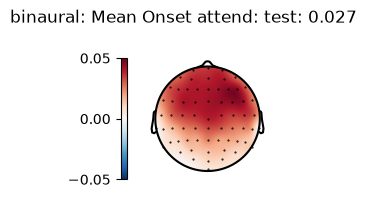

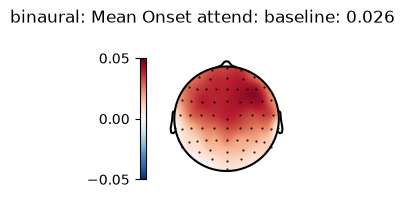

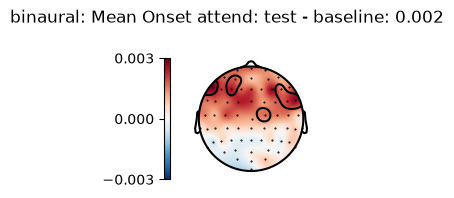

In [7]:
# Onset attend unique contribution (binaural)
# Brodbeck et al. 2020 ran this comparison too: attended onsets unique contribution, t = 6.32, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(ATTEND), 'binaural')
show_topomap_trio(data, diff, result, 'Onset attend', 'binaural', onset(ATTEND))

In [8]:
display(result)
print(f"Onset attend (binaural): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset attend (binaural): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .003>

Onset attend (binaural): ROI unique contribution t(12) = 3.291, p = 0.0032


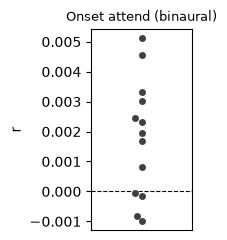

In [9]:
p = show_subject_swarm(diff, 'Onset attend', 'binaural')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


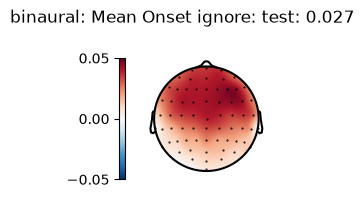

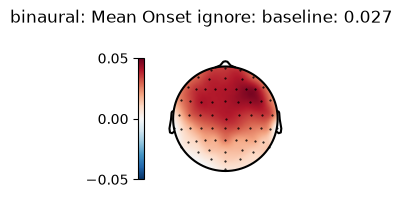

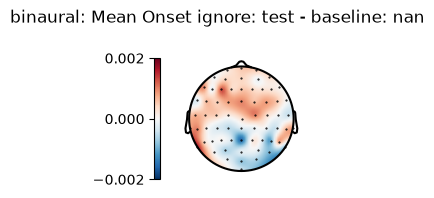

In [10]:
# Onset ignore unique contribution (binaural)
# Brodbeck et al. 2020 ran this comparison too: ignored onsets unique contribution, t = 6.70, p < .001 - the ignored speaker is tracked separately.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(IGNORE), 'binaural')
show_topomap_trio(data, diff, result, 'Onset ignore', 'binaural', onset(IGNORE))

In [11]:
display(result)
print(f"Onset ignore (binaural): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset ignore (binaural): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .267>

Onset ignore (binaural): ROI unique contribution t(12) = 1.329, p = 0.1043


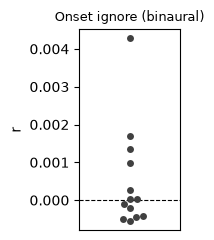

In [12]:
p = show_subject_swarm(diff, 'Onset ignore', 'binaural')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

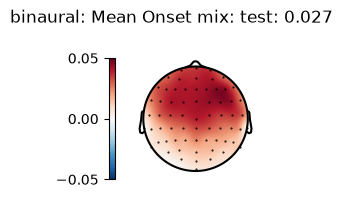

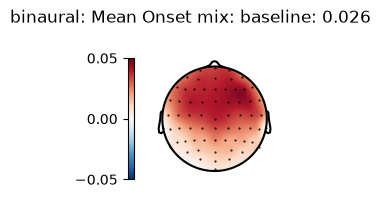

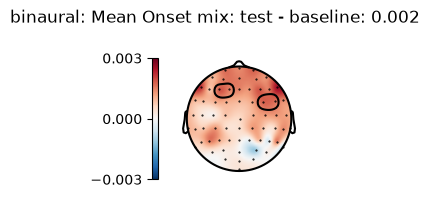

In [13]:
# Onset mix unique contribution (binaural)
# Brodbeck et al. 2020 ran this comparison too: mixture onsets unique contribution, t = 8.61, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, onset(MIX), 'binaural')
show_topomap_trio(data, diff, result, 'Onset mix', 'binaural', onset(MIX))

In [14]:
display(result)
print(f"Onset mix (binaural): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Onset mix (binaural): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .017>

Onset mix (binaural): ROI unique contribution t(12) = 2.794, p = 0.0081


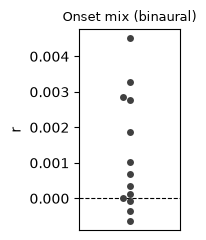

In [15]:
p = show_subject_swarm(diff, 'Onset mix', 'binaural')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


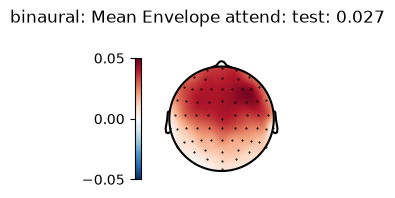

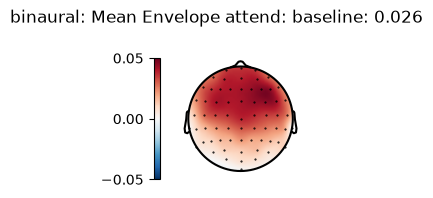

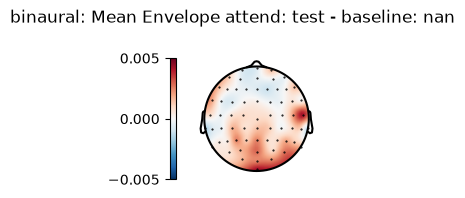

In [16]:
# Envelope attend unique contribution (binaural)
# Brodbeck et al. 2020 ran this comparison too: attended envelope unique contribution, t = 7.37, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(ATTEND), 'binaural')
show_topomap_trio(data, diff, result, 'Envelope attend', 'binaural', envelope(ATTEND))

In [17]:
display(result)
print(f"Envelope attend (binaural): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope attend (binaural): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .560>

Envelope attend (binaural): ROI unique contribution t(12) = 0.048, p = 0.4813


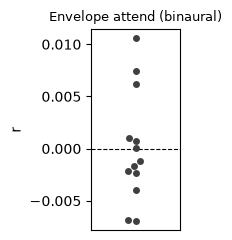

In [18]:
p = show_subject_swarm(diff, 'Envelope attend', 'binaural')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


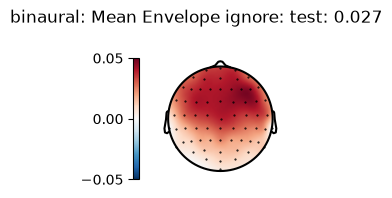

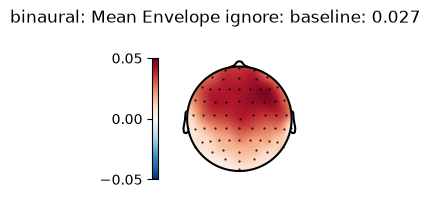

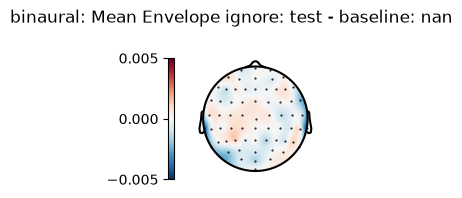

In [19]:
# Envelope ignore unique contribution (binaural)
# Brodbeck et al. 2020 ran this comparison too: ignored envelope unique contribution, t = 6.28, p < .001 - the ignored speaker's envelope is tracked separately too.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(IGNORE), 'binaural')
show_topomap_trio(data, diff, result, 'Envelope ignore', 'binaural', envelope(IGNORE))

In [20]:
display(result)
print(f"Envelope ignore (binaural): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope ignore (binaural): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .663>

Envelope ignore (binaural): ROI unique contribution t(12) = -0.213, p = 0.5826


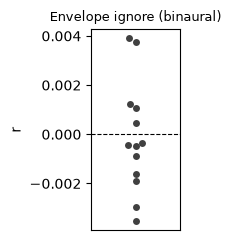

In [21]:
p = show_subject_swarm(diff, 'Envelope ignore', 'binaural')

Permutation test:   0%|          | 0/8191 [00:00<?, ? permutations/s]

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:1063: UserWarning: Warning: converting a masked element to nan.
  mean_value = float(data.mean())


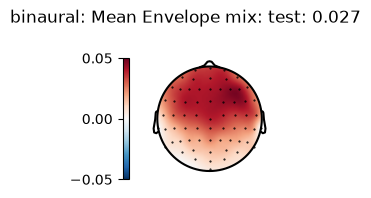

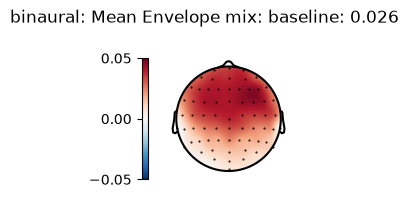

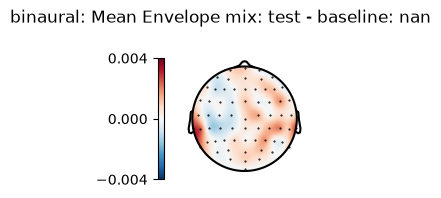

In [22]:
# Envelope mix unique contribution (binaural)
# Brodbeck et al. 2020 ran this comparison too: mixture envelope unique contribution, t = 5.70, p < .001.
data, diff, result = compute_unique_contribution(FULL_BASE, envelope(MIX), 'binaural')
show_topomap_trio(data, diff, result, 'Envelope mix', 'binaural', envelope(MIX))

In [23]:
display(result)
print(f"Envelope mix (binaural): TFCE {tfce_summary(result)}")
ttest = test.TTestOneSample(f'roi_{METRIC}', data=diff, tail=1)
print(f"Envelope mix (binaural): ROI unique contribution t({ttest.df}) = {ttest.t:.3f}, p = {ttest.p:.4f}")

<TTestRelated 'r', 'model', 'test', 'baseline', 'subject' (n=13), tail=1, samples=8191, tfce=True, p = .079>

Envelope mix (binaural): ROI unique contribution t(12) = 0.322, p = 0.3765


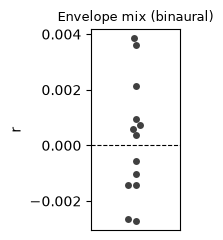

In [24]:
p = show_subject_swarm(diff, 'Envelope mix', 'binaural')

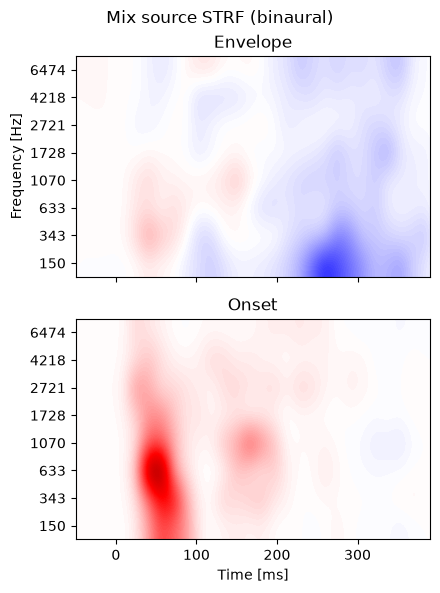

In [25]:
# Mix source STRF: envelope + onset (binaural)
envelope_strf = extract_strf(data_full, 'mix_gammatone_8')
onset_strf = extract_strf(data_full, 'mix_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Mix source STRF (binaural)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

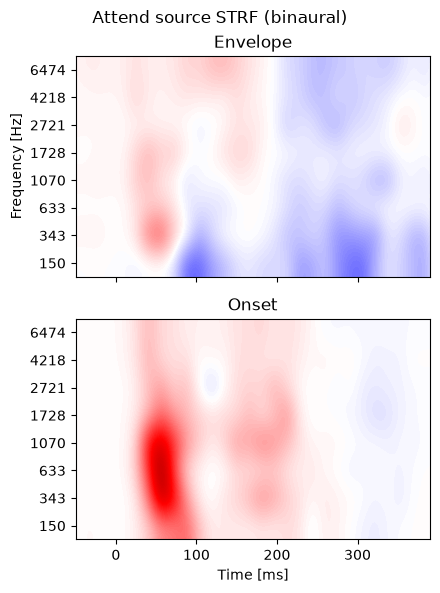

In [26]:
# Attend source STRF: envelope + onset (binaural)
envelope_strf = extract_strf(data_full, 'gammatone_8')
onset_strf = extract_strf(data_full, 'gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Attend source STRF (binaural)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

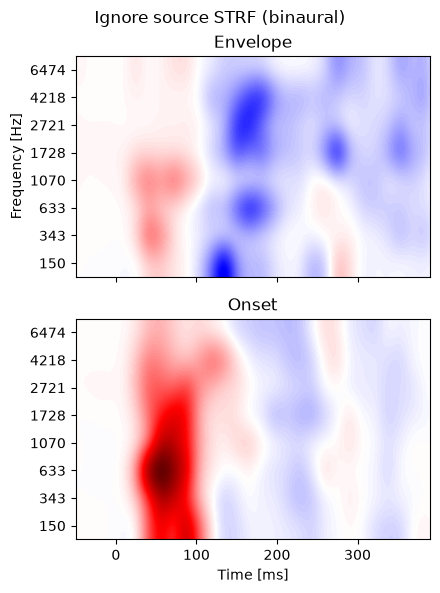

In [27]:
# Ignore source STRF: envelope + onset (binaural)
envelope_strf = extract_strf(data_full, 'bg_gammatone_8')
onset_strf = extract_strf(data_full, 'bg_gammatone_on_8')
p = plot.Array([envelope_strf * 1e3, onset_strf * 1e3], axtitle=['Envelope', 'Onset'],
                title='Ignore source STRF (binaural)', interpolation=STRF_INTERPOLATION, xlim=PLOT_WINDOW)

In [28]:
# Onset attend peak amplitude & timing (binaural)
data = extract_trf(data_full, 'gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset attend (binaural) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset attend (binaural) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset attend (binaural) positive peak: 59 ms, amp 0.005553
Onset attend (binaural) negative peak: 119 ms, amp -0.0001262


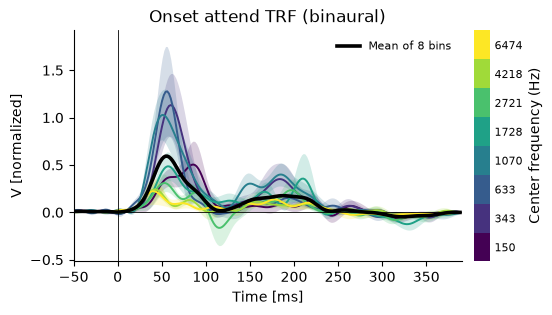

In [29]:
# Onset attend TRF per frequency bin (binaural)
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attend TRF (binaural)')

In [30]:
# Onset ignore peak amplitude & timing (binaural)
data = extract_trf(data_full, 'bg_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset ignore (binaural) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset ignore (binaural) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset ignore (binaural) positive peak: 66 ms, amp 0.003517
Onset ignore (binaural) negative peak: 191 ms, amp -0.0004075


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2097: UserWarning: negative anchor (all) at 199 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


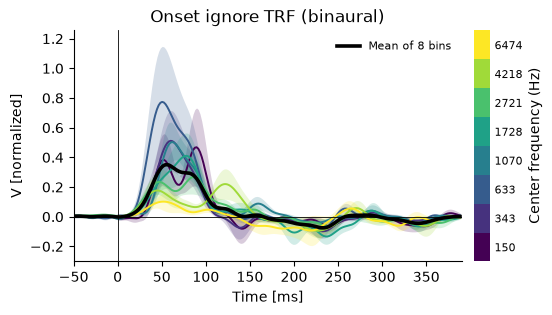

In [31]:
# Onset ignore TRF per frequency bin (binaural)
p = plot_trf_bins(data_full, 'bg_gammatone_on_8', 'Onset ignore TRF (binaural)')

In [32]:
# Onset mix peak amplitude & timing (binaural)
data = extract_trf(data_full, 'mix_gammatone_on_8')
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Onset mix (binaural) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Onset mix (binaural) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Onset mix (binaural) positive peak: 52 ms, amp 0.00724
Onset mix (binaural) negative peak: 111 ms, amp -3.718e-05


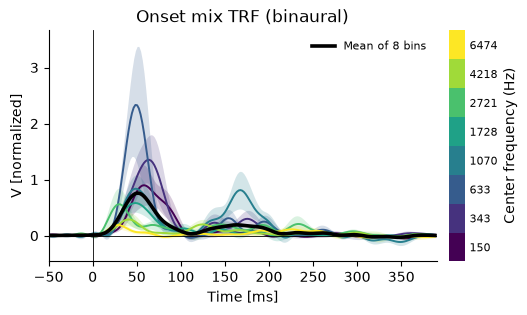

In [33]:
# Onset mix TRF per frequency bin (binaural)
p = plot_trf_bins(data_full, 'mix_gammatone_on_8', 'Onset mix TRF (binaural)')

In [34]:
# Envelope attend peak amplitude & timing (binaural)
data = extract_trf(data_full, 'gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope attend (binaural) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope attend (binaural) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope attend (binaural) positive peak: 52 ms, amp 0.001582
Envelope attend (binaural) negative peak: 109 ms, amp -0.001302


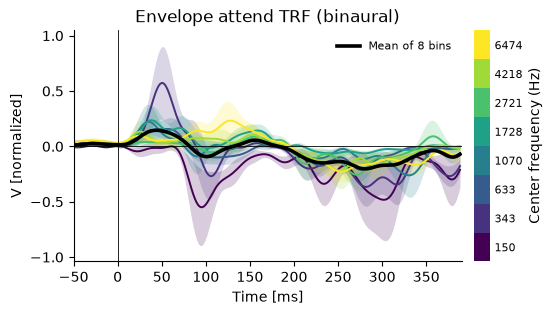

In [35]:
# Envelope attend TRF per frequency bin (binaural)
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attend TRF (binaural)')

In [36]:
# Envelope ignore peak amplitude & timing (binaural)
data = extract_trf(data_full, 'bg_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope ignore (binaural) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope ignore (binaural) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope ignore (binaural) positive peak: 52 ms, amp 0.0008525
Envelope ignore (binaural) negative peak: 165 ms, amp -0.002078


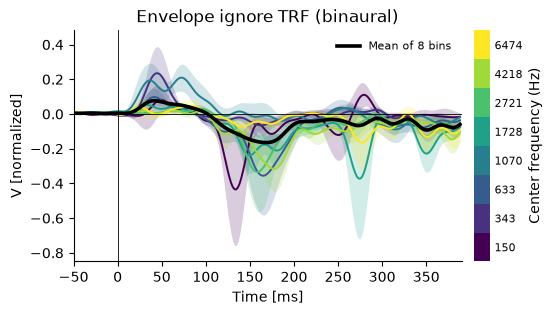

In [37]:
# Envelope ignore TRF per frequency bin (binaural)
p = plot_trf_bins(data_full, 'bg_gammatone_8', 'Envelope ignore TRF (binaural)')

In [38]:
# Envelope mix peak amplitude & timing (binaural)
data = extract_trf(data_full, 'mix_gammatone_8')
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min')
print(f"Envelope mix (binaural) positive peak: {data['positive_time'].mean() * 1e3:.0f} ms, amp {data['positive_amp'].mean():.4g}")
print(f"Envelope mix (binaural) negative peak: {data['negative_time'].mean() * 1e3:.0f} ms, amp {data['negative_amp'].mean():.4g}")

Envelope mix (binaural) positive peak: 47 ms, amp 0.0009783
Envelope mix (binaural) negative peak: 192 ms, amp -0.0006429


/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2097: UserWarning: positive anchor (all) at 41 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")
/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2097: UserWarning: negative anchor (all) at 199 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


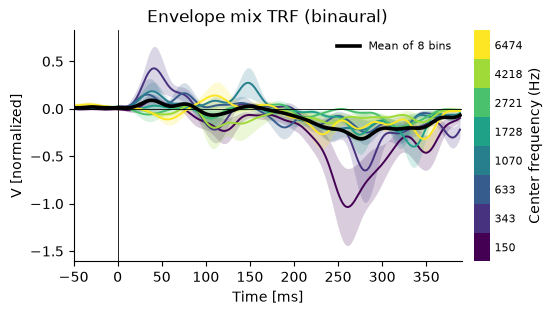

In [39]:
# Envelope mix TRF per frequency bin (binaural)
p = plot_trf_bins(data_full, 'mix_gammatone_8', 'Envelope mix TRF (binaural)')

In [40]:
# Onset peak comparison across mix, attend, and ignore (binaural)
# Brodbeck et al. 2020 ran this comparison too: positive peak latency mixture 72ms, attended 81ms (t=4.47,p<.001), ignored 89ms (t=6.92,p<.001); negative peak latency mixture 138ms, attended 150ms (t=3.20,p=.004); positive peak amplitude bigger for mixture than attended (t=8.41) or ignored (t=7.66).
dss = []
for role_name, column in (('mix', 'mix_gammatone_on_8'), ('attend', 'gammatone_on_8'), ('ignore', 'bg_gammatone_on_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ONSET_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ONSET_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2097: UserWarning: negative anchor (ignore) at 199 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


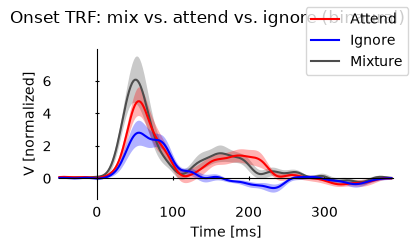

In [41]:
# The onset TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Onset TRF: mix vs. attend vs. ignore (binaural)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [42]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        mix                 72      0.001976
02        mix                 50      0.003758
03        mix                 43      0.005846
04        mix                 41      0.003909
05        mix                 52       0.01313
06        mix                 41      0.007657
07        mix                 48      0.004098
08        mix                 43       0.00739
09        mix                 72      0.009398
10        mix                 56       0.02035
11        mix                 54      0.004333
12        mix                 54      0.001097
13        mix                 50       0.01118
01        attend              80      0.002248
02        attend              60       0.01092
03        attend              41      0.002907
04        attend              56      0.006866
05        attend              48      0.007548
06        attend              46      0.001216
07        attend              46      0.00529

In [43]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='onset positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='onset negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = -3.20** p = .008,t12 = -3.19** p = .008
attend,,t12 = -1.32 p = .210


,attend,ignore
mix,t12 = -2.30* p = .040,t12 = -26.11*** p < .001
attend,,t12 = -15.90*** p < .001


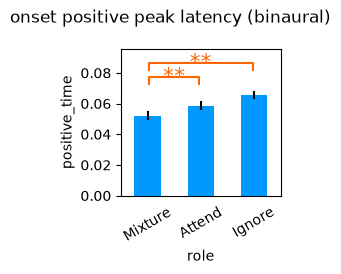

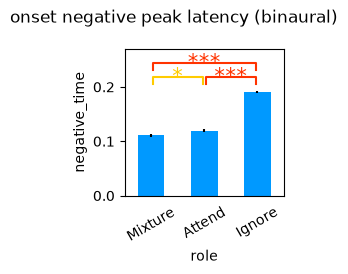

In [44]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak latency (binaural)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak latency (binaural)')
p.set_xtick_rotation(30)

In [45]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='onset positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='onset negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = 1.11 p = .287,t12 = 2.93* p = .013
attend,,t12 = 2.37* p = .036


,attend,ignore
mix,t12 = 0.31 p = .765,t12 = 2.06 p = .061
attend,,t12 = 0.94 p = .367


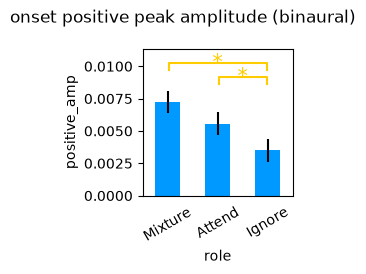

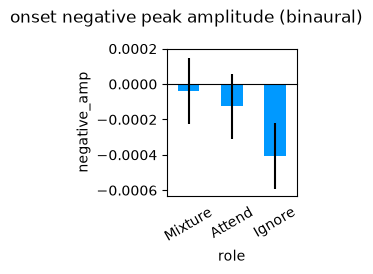

In [46]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset positive peak amplitude (binaural)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='onset negative peak amplitude (binaural)')
p.set_xtick_rotation(30)

In [47]:
# Envelope peak comparison across mix, attend, and ignore (binaural)
dss = []
for role_name, column in (('mix', 'mix_gammatone_8'), ('attend', 'gammatone_8'), ('ignore', 'bg_gammatone_8')):
    ds = extract_trf(data_full, column)
    ds[:, 'role'] = role_name
    dss.append(ds)
data = combine(dss)
data = add_anchored_peak(data, 'positive', ENVELOPE_POSITIVE_PEAK_WINDOW, kind='max', by='role')
data = add_anchored_peak(data, 'negative', ENVELOPE_NEGATIVE_PEAK_WINDOW, kind='min', by='role')

/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2097: UserWarning: positive anchor (mix) at 41 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")
/Users/joshuaighalo/Github Repositories/cocktail-cortical/analysis/experiment.py:2097: UserWarning: negative anchor (mix) at 199 ms is on the edge of the search window (0.04, 0.2)
  warnings.warn(f"{name} anchor ({label}) at {times[i] * 1e3:.0f} ms is on the edge of the search window {window}")


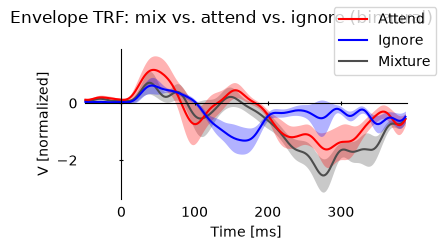

In [48]:
# The envelope TRF waveform mix/attend/ignore were each just measured
# from, overlaid so their shape and relative timing are visible
# directly, not just as extracted peak numbers below.
p = plot.UTSStat('trf_sm*1e3', 'role', data=data, frame='t', h=2.5, w=4, xlim=PLOT_WINDOW,
                  title='Envelope TRF: mix vs. attend vs. ignore (binaural)', labels=LABELS_ROLE, colors=COLORS_ROLE)

In [49]:
print_peak_table(data, 'positive', 'role')
print_peak_table(data, 'negative', 'role')


positive peak
subject   role         time (ms)           amp
01        mix                 64      0.002051
02        mix                 56    -0.0004157
03        mix                 41     0.0003554
04        mix                 41     0.0009267
05        mix                 58     0.0001563
06        mix                 41     5.556e-05
07        mix                 43      0.002229
08        mix                 43      0.003378
09        mix                 64     0.0002818
10        mix                 41       0.00289
11        mix                 41    -6.561e-05
12        mix                 41     -4.31e-06
13        mix                 41     0.0008793
01        attend              58      0.006475
02        attend              56      0.001178
03        attend              62    -0.0001762
04        attend              54      2.72e-05
05        attend              52     0.0004407
06        attend              68      0.001874
07        attend              46     0.000716

In [50]:
display(test.pairwise('positive_time', 'role', match='subject', data=data, corr=False, title='envelope positive peak latency: mix vs. attend vs. ignore'))
display(test.pairwise('negative_time', 'role', match='subject', data=data, corr=False, title='envelope negative peak latency: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = -1.79 p = .098,t12 = -1.65 p = .124
attend,,t12 = 0.00 p = 1.000


,attend,ignore
mix,t12 = 16.59*** p < .001,t12 = 4.13** p = .001
attend,,t12 = -8.62*** p < .001


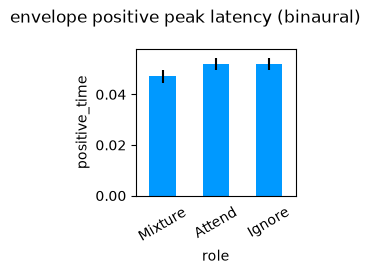

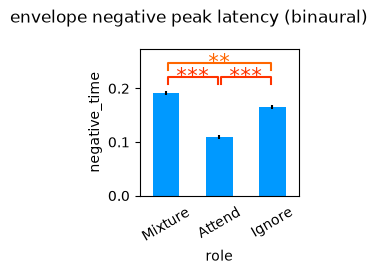

In [51]:
p = plot.Barplot('positive_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak latency (binaural)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_time', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak latency (binaural)')
p.set_xtick_rotation(30)

In [52]:
display(test.pairwise('positive_amp', 'role', match='subject', data=data, corr=False, title='envelope positive peak amplitude: mix vs. attend vs. ignore'))
display(test.pairwise('negative_amp', 'role', match='subject', data=data, corr=False, title='envelope negative peak amplitude: mix vs. attend vs. ignore'))

,attend,ignore
mix,t12 = -1.43 p = .179,t12 = 0.31 p = .760
attend,,t12 = 1.02 p = .329


,attend,ignore
mix,t12 = 1.11 p = .288,t12 = 3.07** p = .010
attend,,t12 = 1.00 p = .339


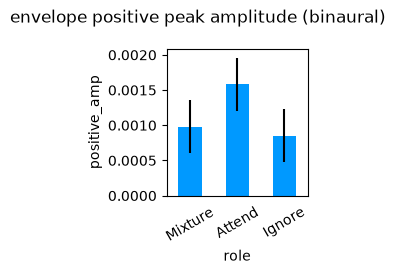

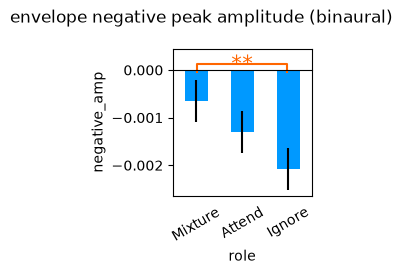

In [53]:
p = plot.Barplot('positive_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope positive peak amplitude (binaural)')
p.set_xtick_rotation(30)
p = plot.Barplot('negative_amp', 'role', match='subject', data=data, h=2.5, w=2.5, labels=LABELS_ROLE, corr=False, title='envelope negative peak amplitude (binaural)')
p.set_xtick_rotation(30)

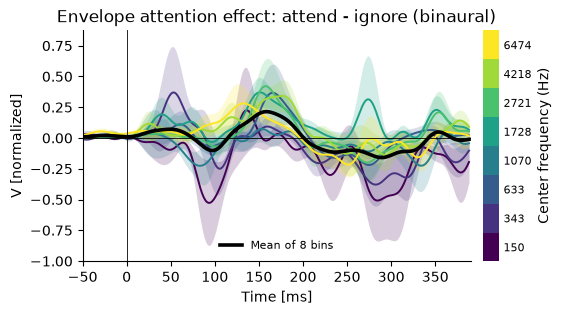

In [54]:
# Envelope attention effect: attend - ignore (binaural)
# Brodbeck et al. 2020 ran this comparison too: envelope attention-effect difference wave: negative bump ~100ms, positive bump ~200ms, starting almost immediately.
p = plot_trf_bins(data_full, 'gammatone_8', 'Envelope attention effect: attend - ignore (binaural)', subtract='bg_gammatone_8')

In [ ]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_full, 'gammatone_8', 'bg_gammatone_8', 'Envelope attention effect: attend - ignore (binaural)')

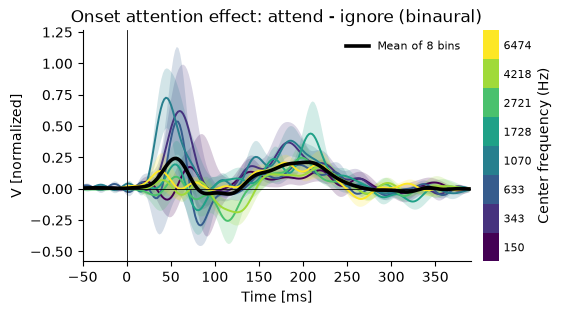

In [55]:
# Onset attention effect: attend - ignore (binaural)
# Brodbeck et al. 2020 ran this comparison too: onset attention effect appears later than the envelope's, once the masked-onset response develops (see the masked-onset section below).
p = plot_trf_bins(data_full, 'gammatone_on_8', 'Onset attention effect: attend - ignore (binaural)', subtract='bg_gammatone_on_8')

In [ ]:
# The same attention effect as one waveform: summed over the frequency bins, mean +- 1 SEM across
# subjects; grey where attend - ignore differs from 0 (TFCE over time, two-tailed).
p = plot_attention_effect(data_full, 'gammatone_on_8', 'bg_gammatone_on_8', 'Onset attention effect: attend - ignore (binaural)')